# 06 — Sequence windows (FD001)

Phase 1 summarised only the last 10 cycles by hand (mean, std, slope). Phase 2 lets the model read the **raw sensor history** instead. This notebook builds that input: **windows**.

A window is the last **W** cycles of one engine × the 14 sensors, a W × 14 table. Its label is the RUL at its last cycle. W = 30 is used by the uncapped models, W = 70 by the capped LSTM.

Rules every window follows:
- it never crosses two engines;
- it ends exactly at the cycle being predicted (no future rows);
- it is scaled with mean and std from the 80 training engines only;
- a short history is padded by repeating the engine's first row at the top.

The code is in `src/sequences.py`. Test labels are not loaded here.

In [1]:
import sys
sys.path.append("../src")
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from load_data import load_train, load_test, SENSORS
from evaluation import split_train_val, CUTOFFS
from sequences import (fit_scaler, scale_by_engine, make_window, early_stop_engines,
                       train_windows, val_windows, test_windows)

## 1. Load, split and fit the scaler on the training engines

In [2]:
train = load_train()
test = load_test()
train_df, val_df = split_train_val(train)
print("training engines:", train_df["engine_id"].nunique(), " validation engines:", val_df["engine_id"].nunique())

mean, std = fit_scaler(train_df)
print(f"sensor_2 mean / std (training engines): {mean['sensor_2']:.4f} / {std['sensor_2']:.4f}")

# Every engine (train, validation, test) is scaled with the same training mean and std.
arrays = scale_by_engine(train, mean, std)
test_arrays = scale_by_engine(test, mean, std)
# RUL per engine, rows in cycle order (same order as the arrays).
rul = {e: rows.sort_values("cycle")["rul"].to_numpy() for e, rows in train.groupby("engine_id")}

training engines: 80  validation engines: 20
sensor_2 mean / std (training engines): 642.6803 / 0.5028


## 2. Early-stopping engines

16 of the 80 training engines are held out from fitting. Training stops when their loss stops improving, so the 20 validation engines stay clean for choosing settings.

In [3]:
es_engines = early_stop_engines(train_df)
fit_engines = sorted(set(train_df["engine_id"]) - set(es_engines))
print("early-stopping engines:", [int(e) for e in es_engines])
print("fitting engines:", len(fit_engines))

early-stopping engines: [2, 3, 6, 16, 23, 26, 40, 44, 51, 57, 58, 67, 71, 75, 88, 97]
fitting engines: 64


## 3. Build the windows for W = 30 and W = 70

In [4]:
windows = {}
for W in (30, 70):
    X_fit, y_fit = train_windows(arrays, rul, fit_engines, W)
    X_es, y_es = train_windows(arrays, rul, es_engines, W)
    X_val = val_windows(arrays, W)
    X_test = test_windows(test_arrays, W)
    windows[W] = dict(X_fit=X_fit, y_fit=y_fit, X_es=X_es, y_es=y_es, X_val=X_val, X_test=X_test)
    print(f"W = {W}")
    print("  fitting windows       ", tuple(X_fit.shape), " labels", tuple(y_fit.shape))
    print("  early-stopping windows", tuple(X_es.shape), " labels", tuple(y_es.shape))
    print("  validation windows    ", tuple(X_val.shape))
    print("  test windows          ", tuple(X_test.shape))

W = 30
  fitting windows        (13118, 30, 14)  labels (13118,)
  early-stopping windows (3272, 30, 14)  labels (3272,)
  validation windows     (100, 30, 14)
  test windows           (100, 30, 14)
W = 70
  fitting windows        (13118, 70, 14)  labels (13118,)
  early-stopping windows (3272, 70, 14)  labels (3272,)
  validation windows     (100, 70, 14)
  test windows           (100, 70, 14)


## 4. Checks

Each check prints `True`.

For the first two checks we replace the sensor values with the **engine id** and the **cycle number** and build the windows the same way. Then a window that mixes engines or looks ahead shows up directly.

In [5]:
W = 30

# Same shapes as the real data, but each value is the engine id / the cycle number.
id_arrays = {e: np.full((len(x), len(SENSORS)), e, dtype="float32") for e, x in arrays.items()}
cycle_arrays = {e: np.repeat(np.arange(1, len(x) + 1, dtype="float32")[:, None], len(SENSORS), axis=1)
                for e, x in arrays.items()}

# a) every window's rows come from one engine
ok = True
for e in fit_engines:
    ids, _ = train_windows(id_arrays, rul, [e], W)
    ok &= bool((ids == e).all())
print("a) every training window comes from one engine:", ok)

# b) no window looks ahead: its newest row is the row it predicts, and its label is that row's RUL
cycles, labels = train_windows(cycle_arrays, rul, fit_engines, W)
expected_cycles = np.concatenate([np.arange(1, len(arrays[e]) + 1) for e in fit_engines])
print("b) each window ends at its own row and no later:",
      bool((cycles[:, -1, 0].numpy() == expected_cycles).all())
      and bool((cycles.max(dim=1).values[:, 0].numpy() == expected_cycles).all()))
print("   labels match that row's RUL:",
      bool((labels.numpy() == train.set_index("engine_id").loc[fit_engines, "rul"].to_numpy()).all()))

# c) validation window 0 ends at engine 8, cycle 41
row = train[(train["engine_id"] == 8) & (train["cycle"] == 41)]
scaled_row = ((row[SENSORS] - mean) / std).to_numpy(dtype="float32")[0]
print("c) validation window 0 is engine", int(CUTOFFS["engine_id"][0]), "cycle", int(CUTOFFS["cycle"][0]), "->",
      np.allclose(windows[W]["X_val"][0, -1].numpy(), scaled_row))

# d) each test window ends at that engine's last row
print("d) every test window ends at its engine's last row:",
      all(np.array_equal(windows[W]["X_test"][i, -1].numpy(), test_arrays[e][-1])
          for i, e in enumerate(sorted(test_arrays))))

# e) a padded window's top rows all equal the engine's first row
short_engine = min(test_arrays, key=lambda e: len(test_arrays[e]))
x = test_arrays[short_engine]
padded = make_window(x, len(x) - 1, 70)
n_pad = 70 - len(x)
print(f"e) test engine {short_engine} has {len(x)} rows; its top {n_pad} rows at W = 70 equal row 1:",
      bool((padded[:n_pad] == x[0]).all()) and np.array_equal(padded[n_pad:], x))

# f) the scaler uses the 80 training engines only
mean_all = train[SENSORS].mean()
print("f) scaler mean = mean over the 80 training engines:", np.allclose(mean, train_df[SENSORS].mean()),
      "| differs from the mean over all 100:", not np.allclose(mean, mean_all))

a) every training window comes from one engine: True


b) each window ends at its own row and no later: True
   labels match that row's RUL: True
c) validation window 0 is engine 8 cycle 41 -> True
d) every test window ends at its engine's last row: True
e) test engine 1 has 31 rows; its top 39 rows at W = 70 equal row 1: True
f) scaler mean = mean over the 80 training engines: True | differs from the mean over all 100: True


## 5. What a window looks like

Engine 1 seen twice with W = 30: once far from failure (window ending at cycle 30) and once at its last cycle, just before failure. Colours are z-scores from the training engines: white is an average reading, red is above average, blue is below.

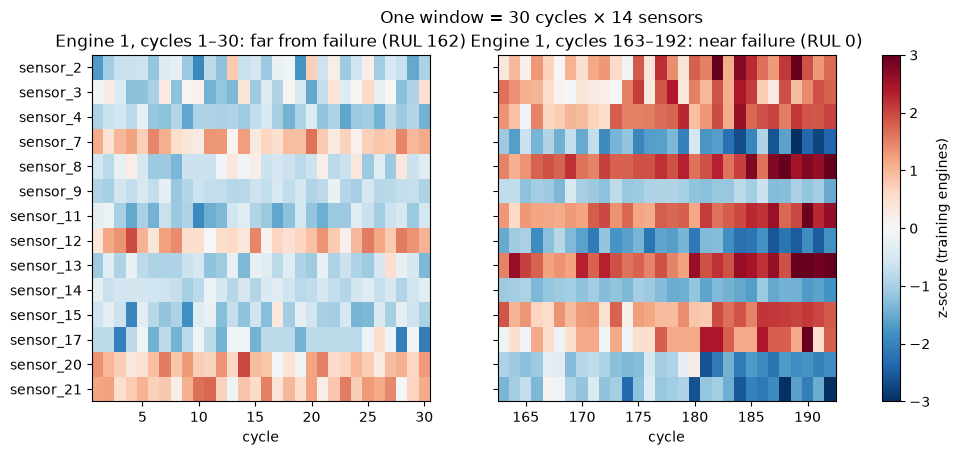

In [6]:
engine = 1
x = arrays[engine]
far = make_window(x, 29, 30)
near = make_window(x, len(x) - 1, 30)
far_rul, near_rul = int(rul[engine][29]), int(rul[engine][-1])

fig, axes = plt.subplots(1, 2, figsize=(12, 4.5), sharey=True)
for ax, window, end_cycle, r, title in [
    (axes[0], far, 30, far_rul, "far from failure"),
    (axes[1], near, len(x), near_rul, "near failure"),
]:
    im = ax.imshow(window.T, aspect="auto", cmap="RdBu_r", vmin=-3, vmax=3,
                   extent=[end_cycle - 29.5, end_cycle + 0.5, len(SENSORS) - 0.5, -0.5])
    ax.set_title(f"Engine {engine}, cycles {end_cycle - 29}–{end_cycle}: {title} (RUL {r})")
    ax.set_xlabel("cycle")
axes[0].set_yticks(range(len(SENSORS)))
axes[0].set_yticklabels(SENSORS)
fig.colorbar(im, ax=axes, label="z-score (training engines)")
fig.suptitle("One window = 30 cycles × 14 sensors")
plt.show()

## 6. How many windows need padding

In [7]:
for W in (30, 70):
    val_pad = int((CUTOFFS["cycle"] < W).sum())
    test_pad = sum(len(x) < W for x in test_arrays.values())
    print(f"W = {W}: validation points needing padding {val_pad} / 100, test engines needing padding {test_pad} / 100")
print("shortest test engine:", min(len(x) for x in test_arrays.values()), "cycles")

W = 30: validation points needing padding 0 / 100, test engines needing padding 0 / 100
W = 70: validation points needing padding 20 / 100, test engines needing padding 14 / 100
shortest test engine: 31 cycles


**Why padding is fine.** Validation cut-offs start at cycle 31 and the shortest test engine has 31 cycles, so at W = 30 nothing is padded. At W = 70, the 20 validation points before cycle 70 and the 14 test engines with fewer than 70 cycles are padded with their own first row. That row is the engine's healthiest reading, so the padded part says "no change yet": it adds no information and takes none from the future. Zero padding would be wrong here, because after scaling 0 means "an average reading", which is a real value.